# 10 · Modelo predictivo ("permite anticipar")

**Pregunta que responde:** ¿la información disponible antes de que el rollo entre al Skinpass (producto, dimensión,
tipo, mes, corona relativa y temperatura de enrollado del MC4) anticipa la corrección de bending Y mejor que una
receta por producto?

Implementa la sección 8.E del plan congelado: **un solo modelo** (gradient boosting) contra una **línea base**
(media de Y por producto × dimensión en entrenamiento), bajo la misma validación agrupada por programa y temporal.
El `KFold` aleatorio se reporta solo para mostrar cuánto infla el desempeño mezclar rollos de un mismo programa.

**Criterio de "mejora clara"** (aclaración operativa; bitácora v1.2): el modelo baja el MAE en las 5 particiones
agrupadas **y** en la temporal. Si no, se reporta como resultado que la información previa al Skinpass no anticipa Y
mejor que el producto. Al final se consolida la tabla completa de contrastes (`contrastes_completos.csv`).

In [1]:
import sys
sys.path.insert(0, "..")

import warnings
warnings.filterwarnings("ignore", category=Warning, module="pandas")

import numpy as np
import pandas as pd

from src import prediccion as pr, skinpass as sk
from src import figuras_articulo as fa
from src.config import TABLAS_DIR
from src.contrastes import consolidar
from src.resultados import fmt, guardar_cifras
from src.visualizacion import estilo_articulo, guardar_articulo

pd.set_option("display.width", 200, "display.max_columns", 30)
estilo_articulo()
m, pz, rs = sk.construir()
a = sk.analitica(m, "paso4")
print(f"{len(a):,} rollos, {a['programa_skp'].nunique()} programas")

44,272 rollos, 831 programas


## 1. Desempeño fuera de muestra: modelo contra línea base

In [2]:
t, imp = pr.evaluar(a)
t.to_csv(TABLAS_DIR / "prediccion_por_particion.csv", index=False)
imp.to_csv(TABLAS_DIR / "prediccion_importancia_permutacion.csv", index=False)
r = pr.resumen(t)
r.to_csv(TABLAS_DIR / "prediccion_resumen.csv", index=False)
print(t[["esquema", "particion", "rollos_prueba", "programas_en_ambos", "MAE_linea_base", "MAE_modelo", "R2_linea_base", "R2_modelo"]].round(3).to_string(index=False))
r.round(3).T

                            esquema  particion  rollos_prueba  programas_en_ambos  MAE_linea_base  MAE_modelo  R2_linea_base  R2_modelo
 Agrupada por programa (GroupKFold)          1           8855                   0         136.848     135.048          0.057      0.092
 Agrupada por programa (GroupKFold)          2           8855                   0         134.026     132.267          0.032      0.064
 Agrupada por programa (GroupKFold)          3           8854                   0         133.668     130.709          0.054      0.092
 Agrupada por programa (GroupKFold)          4           8854                   0         138.067     135.305         -0.011      0.029
 Agrupada por programa (GroupKFold)          5           8854                   0         132.857     131.739          0.036      0.064
       Temporal (ene–ago → sep–nov)          1          11652                   0         142.747     143.583          0.013      0.054
Aleatoria (KFold; mezcla programas)          1  

,0,1,2
esquema,Agrupada por programa (GroupKFold),Temporal (ene–ago → sep–nov),Aleatoria (KFold; mezcla programas)
MAE_modelo_mean,133.014,143.583,128.281
MAE_modelo_std,2.055,NaN,1.666
MAE_linea_base_mean,135.093,142.747,130.488
MAE_linea_base_std,2.241,NaN,1.928
MAE_dif_mean,-2.079,0.836,-2.207
MAE_dif_std,0.766,NaN,0.417
RMSE_modelo_mean,184.335,190.56,178.996
RMSE_modelo_std,4.39,NaN,2.587
RMSE_linea_base_mean,187.743,194.699,182.166


In [3]:
g = t[t["esquema"].str.startswith("Agrupada")]
tm = t[t["esquema"].str.startswith("Temporal")].iloc[0]
mejora_clara = bool((g["MAE_dif"] < 0).all() and tm["MAE_dif"] < 0)
print("¿Mejora clara según el criterio declarado?", mejora_clara)
print("Lo que usa el modelo para predecir (aumento del MAE al permutar cada variable, partición temporal; no es un efecto):")
imp.round(2)

¿Mejora clara según el criterio declarado? False
Lo que usa el modelo para predecir (aumento del MAE al permutar cada variable, partición temporal; no es un efecto):


,variable,aumento_MAE_kN,de
0,Producto,8.19,0.55
4,Corona relativa MC4,0.98,0.11
5,Desv. T. enrollado,0.50,0.07
7,Ancho objetivo,0.31,0.05
1,Dimensión,0.24,0.19
6,Espesor objetivo,0.15,0.14
8,T. enrollado objetivo,0.14,0.02
3,Mes,-0.00,0.04
2,Tipo de material,-0.17,0.03


PosixPath('/Users/emilianolunageorge/Documents/8. TEC/Reto_Ternuim/ternium-matacanes/outputs/figuras/articulo/fig_r5_prediccion.pdf')

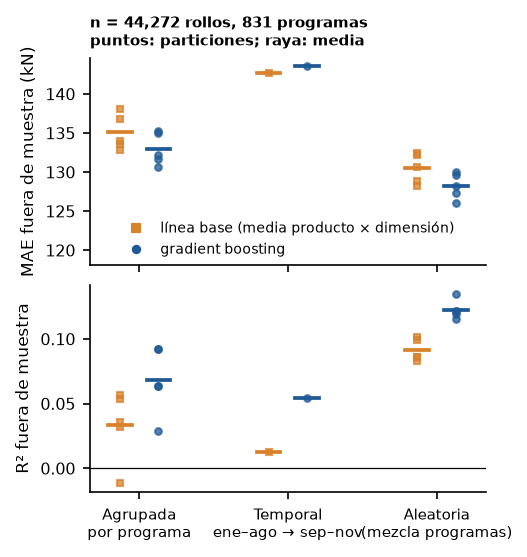

In [4]:
fig = fa.fig_prediccion(t, len(a), a["programa_skp"].nunique())
guardar_articulo(fig, "fig_r5_prediccion")

## 2. Tamaño del efecto y volumen del experimento propuesto (plan, sección 12; bitácora v1.2)

**Tamaño del efecto, fuera de muestra.** ¿Cuánto bajaría |Y| (el trabajo del lazo) si el preset se recentrara con la
corrección histórica? Con las mismas cinco particiones agrupadas por programa se compara |Y| con la receta vigente
(predecir Y = 0) contra |Y − mediana de entrenamiento| para tres recentrados: global, por tipo de material y por celda
producto × dimensión (receta por producto). Se usa la mediana porque minimiza el error absoluto (Y tiene una cola
negativa larga). La diferencia entre el recentrado por producto y el global es lo que **diferenciar por producto**
agregaría a recentrar la receta única.

**Volumen.** Operación evolutiva (Box, 1957) con dos diseños: (i) asignación por programa (el plan v1.1) y (ii)
asignación rollo a rollo **dentro** de cada programa, bloqueada por programa y celda (viable porque el preset ya cambia
entre rollos de un mismo programa, supuesto S3). Para comparar dos brazos de N/2 unidades:
N = 4 (z₀.₉₇₅ + z₀.₈)² σ² / Δ², con σ la DE entre programas de |Y| promedio (diseño i) o la DE de |Y| dentro de
programa × celda (diseño ii).

In [5]:
from scipy import stats as st
from sklearn.model_selection import GroupKFold
d = pr.preparar(a)
z = st.norm.ppf(0.975) + st.norm.ppf(0.80)

def mediana_por(tr, te, claves):
    if not claves:
        return np.full(len(te), tr["y_corr"].median())
    med = tr.groupby(claves)["y_corr"].median()
    p = pd.Series(med.reindex(pd.MultiIndex.from_frame(te[claves]) if len(claves) > 1 else te[claves[0]]).to_numpy(), index=te.index)
    return p.fillna(tr["y_corr"].median()).to_numpy()

ef = []
for k, (i_tr, i_te) in enumerate(GroupKFold(n_splits=5).split(d, groups=d["programa_skp"])):
    tr, te = d.iloc[i_tr], d.iloc[i_te]
    fila = {"particion": k + 1, "receta_vigente": te["y_corr"].abs().mean()}
    for nombre, claves in [("global", []), ("por_tipo", ["tipo"]), ("por_producto_dimension", ["producto", "dimension"])]:
        fila[nombre] = (te["y_corr"] - mediana_por(tr, te, claves)).abs().mean()
    ef.append(fila)
ef = pd.DataFrame(ef)
ef.to_csv(TABLAS_DIR / "experimento_efecto_recentrado.csv", index=False)
delta_cel = (ef["receta_vigente"] - ef["por_producto_dimension"])
delta_glob = (ef["receta_vigente"] - ef["global"])
delta_dif = (ef["global"] - ef["por_producto_dimension"])
print(ef.round(1).to_string(index=False))
print(f"Δ recentrado por producto × dimensión: {delta_cel.mean():.1f} kN (DE {delta_cel.std():.1f}); global: {delta_glob.mean():.1f}; "
      f"lo que agrega diferenciar por producto: {delta_dif.mean():.1f} kN (DE {delta_dif.std():.1f})")

 particion  receta_vigente  global  por_tipo  por_producto_dimension
         1           136.8   130.4     130.4                   127.5
         2           138.4   129.1     129.2                   129.3
         3           129.7   124.9     124.8                   123.4
         4           140.9   131.0     130.9                   131.3
         5           127.0   121.3     121.1                   121.1
Δ recentrado por producto × dimensión: 8.0 kN (DE 1.8); global: 7.2; lo que agrega diferenciar por producto: 0.8 kN (DE 1.4)


In [6]:
d["abs_y"] = d["y_corr"].abs()
d["semana"] = d["fecha_skp"].dt.strftime("%G-W%V")
est_c = pd.read_csv(TABLAS_DIR / "asociacion_principal.csv").iloc[0]
delta_b = abs(est_c["efecto_por_sd"])

def sigmas(sub):
    r = sub["abs_y"] - sub.groupby("celda")["abs_y"].transform("mean")
    gp = r.groupby(sub["programa_skp"]).mean()
    sigma_p = gp[sub.groupby("programa_skp").size() >= 5].std()
    g = sub.groupby(["programa_skp", "celda"])["abs_y"]
    dev = sub["abs_y"] - g.transform("mean")
    n_g = g.transform("size")
    ok = n_g > 1
    sigma_w = np.sqrt((dev[ok] ** 2).sum() / (ok.sum() - sub[ok].groupby(["programa_skp", "celda"]).ngroups))
    return sigma_p, sigma_w

fam = (d.assign(familia=d["tipo"] + " · " + d["norma_l"].astype("string")).groupby("familia").size().sort_values(ascending=False))
familia_top = fam.index[0]
filas = []
for nombre, sub in [("toda la población", d), (familia_top, d[(d["tipo"] + " · " + d["norma_l"].astype("string")) == familia_top])]:
    s_p, s_w = sigmas(sub)
    rollos_sem = sub.groupby("semana").size().median()
    prog_sem = sub.groupby("semana")["programa_skp"].nunique().median()
    for factor, delta in [("A: recentrar el preset por producto × dimensión", delta_cel.mean()),
                          ("A': lo que agrega diferenciar por producto", delta_dif.mean()),
                          ("B: ajustar el preset por la corona", delta_b)]:
        n_p = int(np.ceil(4 * z**2 * s_p**2 / delta**2))
        n_w = int(np.ceil(4 * z**2 * s_w**2 / delta**2))
        filas.append({"poblacion": nombre, "factor": factor, "delta_kN": delta,
                      "sigma_entre_programas": s_p, "programas_necesarios": n_p, "semanas_por_programa": n_p / prog_sem,
                      "sigma_dentro_programa": s_w, "rollos_necesarios": n_w, "semanas_rollo_a_rollo": n_w / rollos_sem,
                      "rollos_por_semana": rollos_sem, "programas_por_semana": prog_sem})
vol = pd.DataFrame(filas)
vol.to_csv(TABLAS_DIR / "experimento_volumen.csv", index=False)
n_a = vol.iloc[0]["rollos_necesarios"]
mde_b = np.sqrt(4 * z**2 * vol.iloc[0]["sigma_dentro_programa"]**2 / n_a)
print(f"Familia más grande: {familia_top} ({fam.iloc[0]:,} rollos). Con N = {n_a:,} rollos, el diseño 2² detecta un efecto de B ≥ {mde_b:.1f} kN.")
vol.round(1)

Familia más grande: DECAPADO · TER (8,342 rollos). Con N = 6,203 rollos, el diseño 2² detecta un efecto de B ≥ 8.0 kN.


,poblacion,factor,delta_kN,sigma_entre_programas,programas_necesarios,semanas_por_programa,sigma_dentro_programa,rollos_necesarios,semanas_rollo_a_rollo,rollos_por_semana,programas_por_semana
0,toda la población,A: recentrar el preset por producto × dimensión,8.0,60.8,1792,94.3,113.1,6203,6.6,936.0,19.0
1,toda la población,A': lo que agrega diferenciar por producto,0.8,60.8,170906,8995.1,113.1,591702,632.2,936.0,19.0
2,toda la población,B: ajustar el preset por la corona,3.9,60.8,7625,401.3,113.1,26399,28.2,936.0,19.0
3,DECAPADO · TER,A: recentrar el preset por producto × dimensión,8.0,65.7,2093,130.8,119.2,6895,42.2,163.5,16.0
4,DECAPADO · TER,A': lo que agrega diferenciar por producto,0.8,65.7,199634,12477.1,119.2,657694,4022.6,163.5,16.0
5,DECAPADO · TER,B: ajustar el preset por la corona,3.9,65.7,8907,556.7,119.2,29344,179.5,163.5,16.0


## 3. Cifras para el texto y tabla completa de contrastes

In [7]:
R = r.set_index("esquema")
ga, te, al = R.iloc[0], R.iloc[1], R.iloc[2]
imp_i = imp.set_index("variable")
c = {
    "PredMAEBaseGrupo": fmt(ga["MAE_linea_base_mean"], 1), "PredMAEModGrupo": fmt(ga["MAE_modelo_mean"], 1),
    "PredMAEDifGrupo": fmt(ga["MAE_dif_mean"], 1), "PredMAEDifGrupoDE": fmt(ga["MAE_dif_std"], 1),
    "PredRBaseGrupo": fmt(ga["R2_linea_base_mean"], 2), "PredRModGrupo": fmt(ga["R2_modelo_mean"], 2),
    "PredRDEModGrupo": fmt(ga["R2_modelo_std"], 2),
    "PredMejoraGrupo": fmt(ga["particiones_donde_modelo_mejora_MAE"], 0),
    "PredMAEBaseTemp": fmt(te["MAE_linea_base_mean"], 1), "PredMAEModTemp": fmt(te["MAE_modelo_mean"], 1),
    "PredRBaseTemp": fmt(te["R2_linea_base_mean"], 2), "PredRModTemp": fmt(te["R2_modelo_mean"], 2),
    "PredMAEBaseAleat": fmt(al["MAE_linea_base_mean"], 1), "PredMAEModAleat": fmt(al["MAE_modelo_mean"], 1),
    "PredRBaseAleat": fmt(al["R2_linea_base_mean"], 2), "PredRModAleat": fmt(al["R2_modelo_mean"], 2),
    "PredMejoraClara": "sí" if mejora_clara else "no",
    "PredImpPrimera": imp.iloc[0]["variable"], "PredImpPrimeraKN": fmt(imp.iloc[0]["aumento_MAE_kN"], 1),
    "PredImpCorona": fmt(imp_i.loc["Corona relativa MC4", "aumento_MAE_kN"], 2),
    "PredImpCoronaRango": f"{int((imp['variable'] == 'Corona relativa MC4').idxmax() if False else list(imp['variable']).index('Corona relativa MC4') + 1)}",
    "PredNTempTrain": fmt(t[t['esquema'].str.startswith('Temporal')]['rollos_entrenamiento'].iat[0], 0),
    "PredNTempTest": fmt(t[t['esquema'].str.startswith('Temporal')]['rollos_prueba'].iat[0], 0),
    "ExpAbsY": fmt(ef["receta_vigente"].mean(), 1), "ExpAbsYCelda": fmt(ef["por_producto_dimension"].mean(), 1),
    "ExpAbsYGlobal": fmt(ef["global"].mean(), 1), "ExpAbsYTipo": fmt(ef["por_tipo"].mean(), 1),
    "ExpDeltaA": fmt(delta_cel.mean(), 1), "ExpDeltaADE": fmt(delta_cel.std(), 1),
    "ExpDeltaGlobal": fmt(delta_glob.mean(), 1), "ExpDeltaDif": fmt(delta_dif.mean(), 1), "ExpDeltaDifDE": fmt(delta_dif.std(), 1),
    "ExpDeltaB": fmt(delta_b, 1), "ExpMDEB": fmt(mde_b, 1),
    "ExpFamilia": familia_top, "ExpFamiliaRollos": fmt(fam.iloc[0], 0),
}
V = vol.set_index(["poblacion", "factor"])
for pob_, k in [("toda la población", "Todo"), (familia_top, "Fam")]:
    for fac, kf in [("A: recentrar el preset por producto × dimensión", "A"),
                    ("A': lo que agrega diferenciar por producto", "Dif"),
                    ("B: ajustar el preset por la corona", "B")]:
        rr = V.loc[(pob_, fac)]
        c[f"Exp{k}{kf}Prog"] = fmt(rr["programas_necesarios"], 0)
        c[f"Exp{k}{kf}SemProg"] = fmt(rr["semanas_por_programa"], 0)
        c[f"Exp{k}{kf}Rollos"] = fmt(rr["rollos_necesarios"], 0)
        c[f"Exp{k}{kf}SemRollo"] = fmt(rr["semanas_rollo_a_rollo"], 1)
    r0 = V.loc[(pob_, "A: recentrar el preset por producto × dimensión")]
    c[f"Exp{k}SigmaProg"] = fmt(r0["sigma_entre_programas"], 1)
    c[f"Exp{k}SigmaDentro"] = fmt(r0["sigma_dentro_programa"], 1)
    c[f"Exp{k}RollosSemana"] = fmt(r0["rollos_por_semana"], 0)
    c[f"Exp{k}ProgSemana"] = fmt(r0["programas_por_semana"], 0)
guardar_cifras(c)
tc = consolidar()
guardar_cifras({"NContrastes": fmt(len(tc), 0)})
print(f"Tabla completa de contrastes: {len(tc)} renglones → outputs/tablas/contrastes_completos.csv")
print(tc["familia"].value_counts().to_string())
c

Tabla completa de contrastes: 104 renglones → outputs/tablas/contrastes_completos.csv
familia
8.D heterogeneidad por producto             35
V3 robustez: pendiente de corona            16
V3 robustez: exceso del grupo − producto    16
Indicadores secundarios                     10
8.E predictivo                               6
8.B descomposición (orden del plan)          4
8.B descomposición (programa primero)        4
V4 programa vs. periodo                      4
12 experimento: tamaño del efecto            4
8.C asociación principal                     2
V1 control negativo                          2
10 confusión no medida                       1


{'PredMAEBaseGrupo': '135.1',
 'PredMAEModGrupo': '133.0',
 'PredMAEDifGrupo': '−2.1',
 'PredMAEDifGrupoDE': '0.8',
 'PredRBaseGrupo': '0.03',
 'PredRModGrupo': '0.07',
 'PredRDEModGrupo': '0.03',
 'PredMejoraGrupo': '5',
 'PredMAEBaseTemp': '142.7',
 'PredMAEModTemp': '143.6',
 'PredRBaseTemp': '0.01',
 'PredRModTemp': '0.05',
 'PredMAEBaseAleat': '130.5',
 'PredMAEModAleat': '128.3',
 'PredRBaseAleat': '0.09',
 'PredRModAleat': '0.12',
 'PredMejoraClara': 'no',
 'PredImpPrimera': 'Producto',
 'PredImpPrimeraKN': '8.2',
 'PredImpCorona': '0.98',
 'PredImpCoronaRango': '2',
 'PredNTempTrain': '32,620',
 'PredNTempTest': '11,652',
 'ExpAbsY': '134.6',
 'ExpAbsYCelda': '126.5',
 'ExpAbsYGlobal': '127.3',
 'ExpAbsYTipo': '127.3',
 'ExpDeltaA': '8.0',
 'ExpDeltaADE': '1.8',
 'ExpDeltaGlobal': '7.2',
 'ExpDeltaDif': '0.8',
 'ExpDeltaDifDE': '1.4',
 'ExpDeltaB': '3.9',
 'ExpMDEB': '8.0',
 'ExpFamilia': 'DECAPADO · TER',
 'ExpFamiliaRollos': '8,342',
 'ExpTodoAProg': '1,792',
 'ExpTodoASemPro